In [ ]:
import pandas as pd
from google.colab import files

arquivo = files.upload()

Saving dataset.csv to dataset.csv


In [ ]:
df = pd.read_csv("dataset.csv")

print("Quantidade de linhas e colunas:", df.shape)

df.head()

Quantidade de linhas e colunas: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# 1. Ver os nomes de todas as colunas
print("COLUNAS DA BASE:")
print(df.columns.tolist())

# 2. Conferir os tipos de dados e valores preenchidos
print("\nINFORMAÇÕES DA BASE")
df.info()

# 3. Contar os valores ausentes em cada coluna
print("\nVALORES AUSENTES:")
print(df.isnull().sum())

COLUNAS DA BASE:
['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

INFORMAÇÕES DA BASE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64

In [ ]:
# 1. Verificar çinhas totalmente duplicadas
print("Linhas totalmente duplicadas:" , df.duplicated().sum())

# 2. Verificar IDs de músicas duplicados
print("IDs de músicas duplicados:" , df["track_id"].duplicated().sum())

# 3. Mostrar as lunhas que possuem dados ausentes
print("\nLinhas com dados ausentes:")
print(df[df[["artists", "album_name", "track_name"]].isnull().any(axis=1)])

# 4. Investigar a coluna Unnamed: 0
print("\nPrimeiros valores do índice original:")
print(df["Unnamed: 0"].head(10).tolist())

print("\nQuantidade de valores diferentes nessa coluna:")
print(df["Unnamed: 0"].nunique())

Linhas totalmente duplicadas: 0
IDs de músicas duplicados: 24259

Linhas com dados ausentes:
       Unnamed: 0                track_id artists album_name track_name  \
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN   

       popularity  duration_ms  explicit  danceability  energy  ...  loudness  \
65900           0            0     False         0.501   0.583  ...     -9.46   

       mode  speechiness  acousticness  instrumentalness  liveness  valence  \
65900     0       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature  track_genre  
65900  138.391               4        k-pop  

[1 rows x 21 columns]

Primeiros valores do índice original:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Quantidade de valores diferentes nessa coluna:
114000


In [ ]:
# Ver um exemplo de música com ID repetido
ids_repetidos = df[df["track_id"].duplicated(keep=False)]

print("Exemplos de IDs repetidos:")
print(
    ids_repetidos[
        ["track_id", "artists", "track_name", "track_genre"]
    ].head(12).to_string(index=False)

)

# Contar quantos IDs únicos existem
print("\nQuantidades de IDs únicos:", df["track_id"].nunique())

# Verificar quantas linhas têm ID repetido, sem contar
# a primeira ocorrência de cada ID
print(
    "Ocorrências adicionais de IDs repetidos:",
    df["track_id"].duplicated().sum()

)

# Conferir se o ID aparece associado a mais de um gênero
generos_por_id = df.groupby("track_id")["track_genre"].nunique()

print(
    "IDs associados com mais de um gênero:",
    (generos_por_id > 1).sum()
)

Exemplos de IDs repetidos:
              track_id                              artists            track_name track_genre
5SuOikwiRyPMVoIQDJUgSV                          Gen Hoshino                Comedy    acoustic
4qPNDBW1i3p13qLCt0Ki3A                         Ben Woodward      Ghost - Acoustic    acoustic
01MVOl9KtVTNfFiBU9I7dc                         Tyrone Wells  Days I Will Remember    acoustic
6Vc5wAMmXdKIAM7WUoEb7N A Great Big World;Christina Aguilera         Say Something    acoustic
1EzrEOXmMH3G43AXT1y7pA                           Jason Mraz             I'm Yours    acoustic
7k9GuJYLp2AzqokyEdwEw2                       Ross Copperman                Hunger    acoustic
4ptDJbJl35d7gQfeNteBwp                             Dan Berk                  Solo    acoustic
0X9MxHR1rTkEHDjp95F2OO                        Anna Hamilton              Bad Liar    acoustic
6xKeQgzfjixSUld14qUezm                 Andrew Foy;Renee Foy ily (i love you baby)    acoustic
4Yo0igmcoNyat1secaH0OD           

In [ ]:
# Quantas linhas existem para cada combinação de música e gênero?
duplicados_muica_genero = df.duplicated(
    subset=["track_id", "track_genre"]
  ).sum()
print(
    "Registros repetidos de música dentro do mesmo gênero:",
    duplicados_muica_genero
)

# Ver exemplos em que o mesmo ID aparece no mesmo gênero
exemplo = df[
    df.duplicated(
        subset=["track_id", "track_genre"],
        keep=False
    )
].sort_values("track_id")

print("\nExemplos:")
print(
    exemplo[
        ["track_id", "artists", "track_name", "track_genre"]
    ].head(10).to_string(index=False)
)


Registros repetidos de música dentro do mesmo gênero: 450

Exemplos:
              track_id                                                                                    artists                                                             track_name track_genre
00JZ83w0Qm09f4PwWj06sM                                                                               George Jones                                              A Good Year For The Roses  honky-tonk
00JZ83w0Qm09f4PwWj06sM                                                                               George Jones                                              A Good Year For The Roses  honky-tonk
02KmEChUwcjxG3G29kbLFT                                   Hans Zimmer;Henning Lohner;Martin Tillman;Fiachra Trench                                                       Shelter Mountain      german
02KmEChUwcjxG3G29kbLFT                                   Hans Zimmer;Henning Lohner;Martin Tillman;Fiachra Trench                              

In [ ]:
# Criar uma cópia do DataFrame original
df_limpo = df.copy()

# Remover registros repetidos da combinação música + gênero
df_limpo = df_limpo.drop_duplicates(
    subset=["track_id", "track_genre"]
)

print("Linhas antes:", len(df))
print("Linhas depois:", len(df_limpo))
print("Linhas removidas:", len(df) - len(df_limpo))

Linhas antes: 114000
Linhas depois: 113550
Linhas removidas: 450


In [ ]:
print("Valores ausentes por coluna:")
print(df_limpo.isnull().sum())

print("\nTotal de valores ausente:")
print(df_limpo.isnull().sum().sum())

Valores ausentes por coluna:
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Total de valores ausente:
3


In [ ]:
# Mostrar o registro que contém dados ausentes
print(df_limpo[df_limpo["track_name"].isnull()])

# Remover registros sem título, artista ou álbum
df_limpo = df_limpo.dropna(
    subset=["track_name", "artists", "album_name"]
)

print("\nTotal de linhas após o tratamento:", len(df_limpo))

print(
    "Total de valores ausentes restantes:",
    df_limpo.isnull().sum().sum()
)

       Unnamed: 0                track_id artists album_name track_name  \
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN   

       popularity  duration_ms  explicit  danceability  energy  ...  loudness  \
65900           0            0     False         0.501   0.583  ...     -9.46   

       mode  speechiness  acousticness  instrumentalness  liveness  valence  \
65900     0       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature  track_genre  
65900  138.391               4        k-pop  

[1 rows x 21 columns]

Total de linhas após o tratamento: 113549
Total de valores ausentes restantes: 0


In [ ]:
# Conferir o tamanho atual da base
print("Total de registros:", len(df_limpo))

print(
    "IDs de músicas únicos:",
    df_limpo["track_id"].nunique()
)

# Salvar uma cópia da base tratada
df_limpo.to_csv(
    "spotify_base_tratada.csv",
    index=False
)

print("Base tratada salva com sucesso!")

Total de registros: 113549
IDs de músicas únicos: 89740
Base tratada salva com sucesso!


In [ ]:
import requests
url = "https://api.spotify.com/v1/tracks/4qPNDBW1i3p13qLCt0Ki3A"

resposta = requests.get(url)

print("Código de resposta:", resposta.status_code)
print(resposta.text[:500])

Código de resposta: 401
{
  "error": {
    "status": 401,
    "message": "Missing/invalid/expired access token"
  }
}



In [ ]:

import requests
from getpass import getpass

client_id = input("Cole o Client ID: ").strip()
client_secret = getpass("Digite o Client Secret (não será exibido): ")

resposta_token = requests.post(
    "https://accounts.spotify.com/api/token",
    data={"grant_type": "client_credentials"},
    auth=(client_id, client_secret)
)

print("Código de autenticação:", resposta_token.status_code)

if resposta_token.status_code == 200:
    token = resposta_token.json()["access_token"]
    print("Token obtido com sucesso!")
else:
    print("Não foi possível autenticar.")
    print(resposta_token.text)


Cole o Client ID: 9b444406b426464fa9fd3c358ecdae01
Digite o Client Secret (não será exibido): ··········
Código de autenticação: 200
Token obtido com sucesso!


In [ ]:
import requests

url = "https://api.spotify.com/v1/tracks/4qPNDBW1i3p13qLCt0Ki3A"

resposta = requests.get(
    url,
    headers={"Authorization": f"Bearer {token}"}
)

print("Código da consulta:", resposta.status_code)

if resposta.status_code == 200:
    dados = resposta.json()

    print("Música:", dados["name"])
    print("Artista(s):", ", ".join(
        artista["name"] for artista in dados["artists"]
    ))
    print("Álbum:", dados["album"]["name"])
    print("Data de lançamento:", dados["album"]["release_date"])
    print("Precisão da data:", dados["album"]["release_date_precision"])
else:
    print("Mensagem:", resposta.text[:1000])

Código da consulta: 200
Música: Ghost - Acoustic
Artista(s): Ben Woodward
Álbum: Ghost (Acoustic)
Data de lançamento: 2021-04-30
Precisão da data: day


In [ ]:
# Selecionar 5 IDs únicos da nossa base
ids_teste = (
    df_limpo["track_id"]
    .dropna()
    .drop_duplicates()
    .head(5)
    .tolist()
)

# Consultar as músicas na API do Spotify
url = "https://api.spotify.com/v1/tracks"

resposta = requests.get(
    url,
    headers={"Authorization": f"Bearer {token}"},
    params={"ids": ",".join(ids_teste)}
)

print("Código da consulta:", resposta.status_code)

if resposta.status_code == 200:
    musicas = resposta.json()["tracks"]

    for musica in musicas:
        if musica is not None:
            print("\nMúsica:", musica["name"])
            print("Artista:", ", ".join(
                artista["name"] for artista in musica["artists"]
            ))
            print("Data de lançamento:", musica["album"]["release_date"])
        else:
            print("\nUma faixa não foi encontrada.")
else:
    print(resposta.text[:1000])

Código da consulta: 403
{"error": {"status": 403, "message": "Forbidden" } }


In [ ]:

import requests
import pandas as pd
import time

resultados = []

ids_teste = (
    df_limpo["track_id"]
    .dropna()
    .drop_duplicates()
    .head(5)
    .tolist()
)

for track_id in ids_teste:
    url = f"https://api.spotify.com/v1/tracks/{track_id}"

    resposta = requests.get(
        url,
        headers={"Authorization": f"Bearer {token}"}
    )

    if resposta.status_code == 200:
        musica = resposta.json()

        resultados.append({
            "track_id": track_id,
            "musica": musica["name"],
            "artistas": ", ".join(
                artista["name"] for artista in musica["artists"]
            ),
            "album": musica["album"]["name"],
            "data_lancamento": musica["album"]["release_date"],
            "precisao_data": musica["album"]["release_date_precision"]
        })

    else:
        print(
            "Falha na faixa", track_id,
            "| Código:", resposta.status_code
        )

    time.sleep(0.2)

df_teste_datas = pd.DataFrame(resultados)

print("Faixas encontradas:", len(df_teste_datas))
display(df_teste_datas)


Faixas encontradas: 5


,track_id,musica,artistas,album,data_lancamento,precisao_data
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,Comedy,2022-04-08,day
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,Ghost (Acoustic),2021-04-30,day
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,"Ingrid Michaelson, ZAYN",To Begin Again,2021-03-17,day
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,2018-08-10,day
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,Hold On,2017-02-03,day


In [ ]:
# Selecionar 100 músicas com IDs únicos
ids_teste_100 = (
    df_limpo["track_id"]
    .dropna()
    .drop_duplicates()
    .head(100)
    .tolist()
)

print("Quantidade de músicas selecionadas:", len(ids_teste_100))

Quantidade de músicas selecionadas: 100


In [ ]:

import requests
import pandas as pd
import time

resultados_100 = []
falhas_100 = []

for i, track_id in enumerate(ids_teste_100, start=1):
    url = f"https://api.spotify.com/v1/tracks/{track_id}"

    resposta = requests.get(
        url,
        headers={"Authorization": f"Bearer {token}"},
        timeout=15
    )

    if resposta.status_code == 200:
        musica = resposta.json()

        resultados_100.append({
            "track_id": track_id,
            "musica": musica["name"],
            "artistas": ", ".join(
                artista["name"] for artista in musica["artists"]
            ),
            "album": musica["album"]["name"],
            "data_lancamento": musica["album"]["release_date"],
            "precisao_data": musica["album"]["release_date_precision"]
        })
    else:
        falhas_100.append({
            "track_id": track_id,
            "codigo": resposta.status_code
        })

    if i % 20 == 0:
        print(f"Consultadas: {i}/100")

    time.sleep(0.2)

df_datas_100 = pd.DataFrame(resultados_100)

print("\nConsulta concluída!")
print("Datas recuperadas:", len(df_datas_100))
print("Falhas:", len(falhas_100))

display(df_datas_100.head(10))

if falhas_100:
    display(pd.DataFrame(falhas_100).head(10))


Consultadas: 20/100
Consultadas: 40/100
Consultadas: 60/100
Consultadas: 80/100
Consultadas: 100/100

Consulta concluída!
Datas recuperadas: 100
Falhas: 0


,track_id,musica,artistas,album,data_lancamento,precisao_data
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,Comedy,2022-04-08,day
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,Ghost (Acoustic),2021-04-30,day
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,"Ingrid Michaelson, ZAYN",To Begin Again,2021-03-17,day
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,2018-08-10,day
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,Hold On,2017-02-03,day
5,01MVOl9KtVTNfFiBU9I7dc,Days I Will Remember,Tyrone Wells,Days I Will Remember,2018-04-20,day
6,6Vc5wAMmXdKIAM7WUoEb7N,Say Something,"A Great Big World, Christina Aguilera",Is There Anybody Out There?,2014-01-20,day
7,1EzrEOXmMH3G43AXT1y7pA,I'm Yours,Jason Mraz,We Sing. We Dance. We Steal Things.,2008-05-01,day
8,0IktbUcnAGrvD03AWnz3Q8,Lucky,"Jason Mraz, Colbie Caillat",We Sing. We Dance. We Steal Things.,2008-05-01,day
9,7k9GuJYLp2AzqokyEdwEw2,Hunger,Ross Copperman,Hunger,2015-04-21,day


In [ ]:

# Criar uma cópia das datas recuperadas
df_datas_100 = df_datas_100.copy()

# Extrair o ano da data de lançamento
df_datas_100["ano_lancamento"] = pd.to_numeric(
    df_datas_100["data_lancamento"].str[:4],
    errors="coerce"
).astype("Int64")

# Conferir os resultados
display(
    df_datas_100[
        ["musica", "data_lancamento", "ano_lancamento"]
    ].head(10)
)

print(
    "Anos de lançamento encontrados:",
    df_datas_100["ano_lancamento"].nunique()
)


,musica,data_lancamento,ano_lancamento
0,Comedy,2022-04-08,2022
1,Ghost - Acoustic,2021-04-30,2021
2,To Begin Again,2021-03-17,2021
3,Can't Help Falling In Love,2018-08-10,2018
4,Hold On,2017-02-03,2017
5,Days I Will Remember,2018-04-20,2018
6,Say Something,2014-01-20,2014
7,I'm Yours,2008-05-01,2008
8,Lucky,2008-05-01,2008
9,Hunger,2015-04-21,2015


Anos de lançamento encontrados: 17


,quantidade_musicas
ano_lancamento,
2000,1
2007,3
2008,5
2009,1
2010,3
2011,1
2012,3
2013,5
2014,2


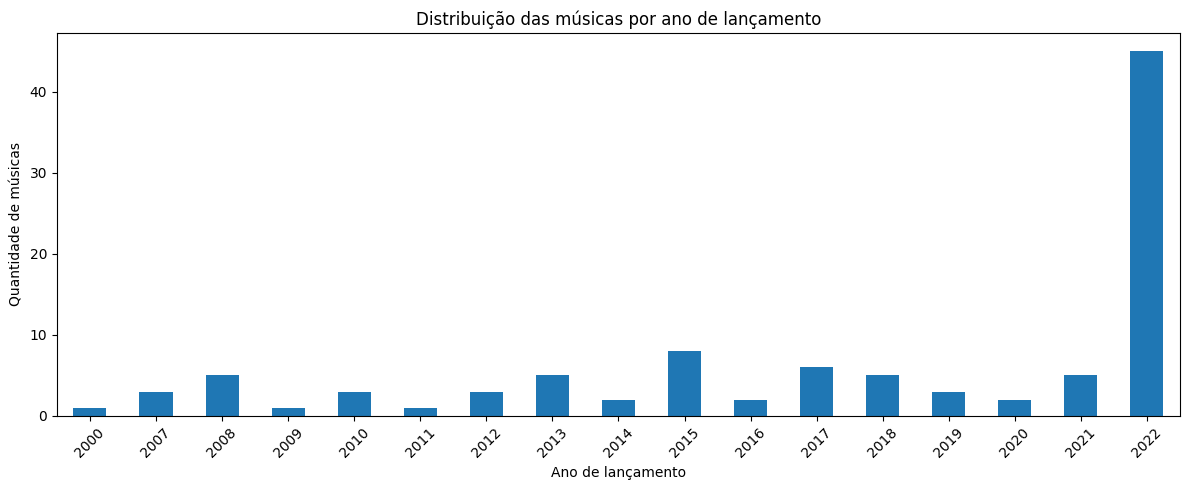

In [ ]:

# Contar quantas músicas existem por ano de lançamento
distribuicao_anos = (
    df_datas_100["ano_lancamento"]
    .value_counts()
    .sort_index()
)

display(distribuicao_anos.to_frame(name="quantidade_musicas"))

# Criar um gráfico de barras
import matplotlib.pyplot as plt

distribuicao_anos.plot(kind="bar", figsize=(12, 5))

plt.title("Distribuição das músicas por ano de lançamento")
plt.xlabel("Ano de lançamento")
plt.ylabel("Quantidade de músicas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# Verificar os primeiros gêneros da base
print("Distribuição dos gêneros nas primeiras 100 linhas:")
display(df_limpo["track_genre"].head(100).value_counts())

# Verificar os gêneros na base completa
print("\nQuantidade de gêneros diferentes na base:")
print(df_limpo["track_genre"].nunique())

print("\nPrimeiros 20 gêneros encontrados:")
display(df_limpo["track_genre"].drop_duplicates().head(20))


Distribuição dos gêneros nas primeiras 100 linhas:


,count
track_genre,
acoustic,100



Quantidade de gêneros diferentes na base:
114

Primeiros 20 gêneros encontrados:


,track_genre
0,acoustic
1000,afrobeat
2000,alt-rock
3000,alternative
4000,ambient
5000,anime
6000,black-metal
7000,bluegrass
8000,blues
9000,brazil


In [ ]:

# Selecionar a primeira música de cada gênero
amostra_generos = (
    df_limpo
    .drop_duplicates(subset=["track_genre"])
    [["track_id", "track_genre", "track_name", "artists"]]
    .reset_index(drop=True)
)

print("Quantidade de músicas selecionadas:", len(amostra_generos))

display(amostra_generos.head(15))


Quantidade de músicas selecionadas: 114


,track_id,track_genre,track_name,artists
0,5SuOikwiRyPMVoIQDJUgSV,acoustic,Comedy,Gen Hoshino
1,4pR4oQJULf7FDB54TleMyH,afrobeat,Jireh (My Provider),Limoblaze;Lecrae;Happi
2,5E30LdtzQTGqRvNd7l6kG5,alt-rock,Daddy Issues,The Neighbourhood
3,5E30LdtzQTGqRvNd7l6kG5,alternative,Daddy Issues,The Neighbourhood
4,1FWsomP9StpCcXNWmJk8Cl,ambient,K.,Cigarettes After Sex
5,1gUAX2ImxDsB3YDcyxMXlB,anime,カワキヲアメク,美波
6,0mJUxFpEI1eAOIIfnNoZ4G,black-metal,Hallowed Be Thy Name,Cradle Of Filth
7,5qm0KiVKMXW1kq6VrnIhz5,bluegrass,Cliffs Of Dover - Instrumental,Eric Johnson
8,5MAK1nd8R6PWnle1Q1WJvh,blues,I See Red,Everybody Loves an Outlaw
9,6GomT970rCOkKAyyrwJeZi,brazil,Move Your Body,Öwnboss;Sevek


In [ ]:

import requests
import pandas as pd
import time

resultados_generos = []
falhas_generos = []

for i, linha in enumerate(amostra_generos.itertuples(index=False), start=1):
    track_id = linha.track_id

    url = f"https://api.spotify.com/v1/tracks/{track_id}"

    try:
        resposta = requests.get(
            url,
            headers={"Authorization": f"Bearer {token}"},
            timeout=15
        )

        if resposta.status_code == 200:
            musica = resposta.json()
            data = musica["album"]["release_date"]

            resultados_generos.append({
                "track_id": track_id,
                "genero": linha.track_genre,
                "musica": musica["name"],
                "artistas": ", ".join(
                    artista["name"] for artista in musica["artists"]
                ),
                "data_lancamento": data,
                "ano_lancamento": int(data[:4]) if data else None,
                "precisao_data": musica["album"]["release_date_precision"]
            })
        else:
            falhas_generos.append({
                "track_id": track_id,
                "genero": linha.track_genre,
                "codigo": resposta.status_code
            })

    except requests.RequestException as erro:
        falhas_generos.append({
            "track_id": track_id,
            "genero": linha.track_genre,
            "codigo": str(erro)
        })

    if i % 20 == 0:
        print(f"Consultadas: {i}/{len(amostra_generos)}")

    time.sleep(0.2)

df_datas_generos = pd.DataFrame(resultados_generos)

print("\nConsulta concluída!")
print("Datas recuperadas:", len(df_datas_generos))
print("Falhas:", len(falhas_generos))

display(df_datas_generos.head(10))


Consultadas: 20/114
Consultadas: 40/114
Consultadas: 60/114
Consultadas: 80/114
Consultadas: 100/114

Consulta concluída!
Datas recuperadas: 114
Falhas: 0


,track_id,genero,musica,artistas,data_lancamento,ano_lancamento,precisao_data
0,5SuOikwiRyPMVoIQDJUgSV,acoustic,Comedy,Gen Hoshino,2022-04-08,2022,day
1,4pR4oQJULf7FDB54TleMyH,afrobeat,Jireh (My Provider),"Limoblaze, Lecrae, Happi",2022-07-01,2022,day
2,5E30LdtzQTGqRvNd7l6kG5,alt-rock,Daddy Issues,The Neighbourhood,2015-10-30,2015,day
3,5E30LdtzQTGqRvNd7l6kG5,alternative,Daddy Issues,The Neighbourhood,2015-10-30,2015,day
4,1FWsomP9StpCcXNWmJk8Cl,ambient,K.,Cigarettes After Sex,2017-06-09,2017,day
5,1gUAX2ImxDsB3YDcyxMXlB,anime,カワキヲアメク,美波,2019-01-30,2019,day
6,0mJUxFpEI1eAOIIfnNoZ4G,black-metal,Hallowed Be Thy Name,Cradle Of Filth,2002-09-26,2002,day
7,5qm0KiVKMXW1kq6VrnIhz5,bluegrass,Cliffs Of Dover - Instrumental,Eric Johnson,1990,1990,year
8,5MAK1nd8R6PWnle1Q1WJvh,blues,I See Red,Everybody Loves an Outlaw,2018-10-31,2018,day
9,6GomT970rCOkKAyyrwJeZi,brazil,Move Your Body,"Öwnboss, Sevek",2021-10-29,2021,day


In [ ]:

# Quantidade de registros e músicas únicas na amostra
print("Registros consultados:", len(df_datas_generos))

print(
    "IDs de músicas únicos:",
    df_datas_generos["track_id"].nunique()
)

print(
    "Anos de lançamento diferentes:",
    df_datas_generos["ano_lancamento"].nunique()
)

print(
    "Datas sem dia e mês:",
    (df_datas_generos["precisao_data"] == "year").sum()
)

# Verificar músicas que aparecem associadas a mais de um gênero
generos_por_musica = (
    df_datas_generos.groupby("track_id")["genero"]
    .nunique()
)

print(
    "IDs associados a mais de um gênero na amostra:",
    (generos_por_musica > 1).sum()
)


Registros consultados: 114
IDs de músicas únicos: 103
Anos de lançamento diferentes: 30
Datas sem dia e mês: 3
IDs associados a mais de um gênero na amostra: 10


In [ ]:

# Criar uma tabela com uma linha por música
df_lancamentos = (
    df_datas_generos[
        [
            "track_id",
            "musica",
            "artistas",
            "data_lancamento",
            "ano_lancamento",
            "precisao_data"
        ]
    ]
    .drop_duplicates(subset=["track_id"])
    .reset_index(drop=True)
)

print("Linhas na tabela de lançamentos:", len(df_lancamentos))
print("IDs únicos:", df_lancamentos["track_id"].nunique())
print("Valores de ano ausentes:", df_lancamentos["ano_lancamento"].isna().sum())

display(df_lancamentos.head(10))


Linhas na tabela de lançamentos: 103
IDs únicos: 103
Valores de ano ausentes: 0


,track_id,musica,artistas,data_lancamento,ano_lancamento,precisao_data
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,2022-04-08,2022,day
1,4pR4oQJULf7FDB54TleMyH,Jireh (My Provider),"Limoblaze, Lecrae, Happi",2022-07-01,2022,day
2,5E30LdtzQTGqRvNd7l6kG5,Daddy Issues,The Neighbourhood,2015-10-30,2015,day
3,1FWsomP9StpCcXNWmJk8Cl,K.,Cigarettes After Sex,2017-06-09,2017,day
4,1gUAX2ImxDsB3YDcyxMXlB,カワキヲアメク,美波,2019-01-30,2019,day
5,0mJUxFpEI1eAOIIfnNoZ4G,Hallowed Be Thy Name,Cradle Of Filth,2002-09-26,2002,day
6,5qm0KiVKMXW1kq6VrnIhz5,Cliffs Of Dover - Instrumental,Eric Johnson,1990,1990,year
7,5MAK1nd8R6PWnle1Q1WJvh,I See Red,Everybody Loves an Outlaw,2018-10-31,2018,day
8,6GomT970rCOkKAyyrwJeZi,Move Your Body,"Öwnboss, Sevek",2021-10-29,2021,day
9,3JiyUyibMs31de0hmoeSK9,Speakerbox (feat. Ohana Bam & Lafa Taylor) - F...,"Bassnectar, Ohana Bam, Lafa Taylor",2017-04-14,2017,day


In [ ]:

# Fazer uma junção de teste, preservando todas as linhas da base tratada
df_teste_merge = df_limpo.merge(
    df_lancamentos[["track_id", "ano_lancamento"]],
    on="track_id",
    how="left"
)

print("Linhas na base original:", len(df_limpo))
print("Linhas após a junção:", len(df_teste_merge))

print(
    "Registros com ano de lançamento:",
    df_teste_merge["ano_lancamento"].notna().sum()
)

print(
    "Registros sem ano de lançamento:",
    df_teste_merge["ano_lancamento"].isna().sum()
)

display(
    df_teste_merge[
        ["track_name", "artists", "track_genre", "ano_lancamento"]
    ].head(10)
)


Linhas na base original: 113549
Linhas após a junção: 113549
Registros com ano de lançamento: 245
Registros sem ano de lançamento: 113304


,track_name,artists,track_genre,ano_lancamento
0,Comedy,Gen Hoshino,acoustic,2022.0
1,Ghost - Acoustic,Ben Woodward,acoustic,NaN
2,To Begin Again,Ingrid Michaelson;ZAYN,acoustic,NaN
3,Can't Help Falling In Love,Kina Grannis,acoustic,NaN
4,Hold On,Chord Overstreet,acoustic,NaN
5,Days I Will Remember,Tyrone Wells,acoustic,NaN
6,Say Something,A Great Big World;Christina Aguilera,acoustic,NaN
7,I'm Yours,Jason Mraz,acoustic,NaN
8,Lucky,Jason Mraz;Colbie Caillat,acoustic,NaN
9,Hunger,Ross Copperman,acoustic,NaN


In [ ]:

import requests

url = (
    "https://huggingface.co/api/datasets/"
    "khushimalviya/spotify-tracks-dataset"
)

resposta = requests.get(url, timeout=30)

print("Código da consulta:", resposta.status_code)

if resposta.status_code == 200:
    dados_dataset = resposta.json()

    print("\nArquivos disponíveis:")
    for arquivo in dados_dataset.get("siblings", []):
        print(arquivo.get("rfilename"))
else:
    print("Não foi possível consultar os arquivos agora.")


Código da consulta: 200

Arquivos disponíveis:
.gitattributes
spotify_tracks.csv


In [ ]:

import pandas as pd

url_csv = (
    "https://huggingface.co/datasets/"
    "khushimalviya/spotify-tracks-dataset/"
    "resolve/main/spotify_tracks.csv"
)

df_complementar = pd.read_csv(url_csv, nrows=5)

print("Colunas disponíveis:")
print(df_complementar.columns.tolist())

print("\nPrimeiras 5 linhas:")
display(df_complementar)


Colunas disponíveis:
['id', 'name', 'popularity', 'duration_ms', 'explicit', 'artists', 'id_artists', 'release_date', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

Primeiras 5 linhas:


,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,['Uli'],['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,0,-13.338,1,0.4510,0.674,0.7440,0.151,0.127,104.851,3
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,['Fernando Pessoa'],['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,0,-22.136,1,0.9570,0.797,0.0000,0.148,0.655,102.009,1
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,1,-21.180,1,0.0512,0.994,0.0218,0.212,0.457,130.418,5
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,7,-27.961,1,0.0504,0.995,0.9180,0.104,0.397,169.980,3
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,['Dick Haymes'],['3BiJGZsyX9sJchTqcSA7Su'],1922,0.402,0.1580,3,-16.900,0,0.0390,0.989,0.1300,0.311,0.196,103.220,4


In [ ]:

# Comparar os IDs da base principal com os da complementar
ids_principais = set(df_limpo["track_id"].dropna())

ids_complementares = set(
    df_complementar["id"].dropna()
)

print("IDs únicos na base principal:", len(ids_principais))
print("IDs únicos na amostra complementar:", len(ids_complementares))

print(
    "Correspondências na amostra carregada:",
    len(ids_principais & ids_complementares)
)


IDs únicos na base principal: 89740
IDs únicos na amostra complementar: 5
Correspondências na amostra carregada: 0


In [ ]:

import pandas as pd

# IDs das músicas da nossa base principal
ids_principais = set(df_limpo["track_id"].dropna().unique())

# Endereço do arquivo complementar
url_csv = "https://huggingface.co/datasets/khushimalviya/spotify-tracks-dataset/resolve/main/spotify_tracks.csv"

# Procurar correspondências por blocos
correspondencias = []

for bloco in pd.read_csv(
    url_csv,
    usecols=["id", "release_date"],
    chunksize=50000
):
    encontrados = bloco[bloco["id"].isin(ids_principais)]

    if not encontrados.empty:
        correspondencias.append(encontrados)

# Juntar os resultados encontrados
if correspondencias:
    df_correspondencias = pd.concat(
        correspondencias,
        ignore_index=True
    )
else:
    df_correspondencias = pd.DataFrame(
        columns=["id", "release_date"]
    )

print("Registros encontrados:", len(df_correspondencias))
print("IDs únicos encontrados:", df_correspondencias["id"].nunique())
print("Datas de lançamento disponíveis:", df_correspondencias["release_date"].notna().sum())


Registros encontrados: 17001
IDs únicos encontrados: 17001
Datas de lançamento disponíveis: 17001


In [ ]:

# Criar uma cópia para tratar as datas sem alterar o resultado original
df_lancamentos = df_correspondencias.copy()

# Limpar espaços e padronizar as datas como texto
df_lancamentos["release_date"] = (
    df_lancamentos["release_date"]
    .astype("string")
    .str.strip()
)

# Extrair os quatro primeiros caracteres e converter em ano
df_lancamentos["ano_lancamento"] = pd.to_numeric(
    df_lancamentos["release_date"].str[:4],
    errors="coerce"
).astype("Int64")

print("Registros:", len(df_lancamentos))
print("Anos válidos:", df_lancamentos["ano_lancamento"].notna().sum())
print("\nPrimeiras linhas:")
display(df_lancamentos.head())

print("\nResumo dos anos:")
display(df_lancamentos["ano_lancamento"].describe())


Registros: 17001
Anos válidos: 17001

Primeiras linhas:


,id,release_date,ano_lancamento
0,4KYPfZpN9haysWIStzfr3k,1927-05-14,1927
1,0wwyjolxUZ5GEYghs8XHwi,1928-05-14,1928
2,1HZiHEA6MVMCSzEE2VlV4j,1930-08-18,1930
3,6MdjSQPkhUnlkP0yptEmbF,1931-01-01,1931
4,6fyDrjv9BKI39ZqvjHOflO,1931-01-01,1931



Resumo dos anos:


,ano_lancamento
count,17001.0
mean,2002.10517
std,15.080162
min,1927.0
25%,1994.0
50%,2006.0
75%,2014.0
max,2021.0


In [ ]:

# Contar quantas músicas correspondem a cada ano
musicas_por_ano = (
    df_lancamentos["ano_lancamento"]
    .value_counts()
    .sort_index()
)

print("Quantidade de anos diferentes:", musicas_por_ano.size)

print("\n10 anos com mais registros:")
display(
    musicas_por_ano
    .sort_values(ascending=False)
    .head(10)
    .rename("quantidade_musicas")
    .to_frame()
)

print("\n10 anos com menos registros:")
display(
    musicas_por_ano
    .sort_values()
    .head(10)
    .rename("quantidade_musicas")
    .to_frame()
)


Quantidade de anos diferentes: 83

10 anos com mais registros:


,quantidade_musicas
ano_lancamento,
2019,701
2018,697
2020,659
2017,643
2016,628
2015,593
2013,585
2014,555
2012,532



10 anos com menos registros:


,quantidade_musicas
ano_lancamento,
1927,1
1928,1
1930,1
1932,1
1937,1
1935,1
1940,1
1948,2
1953,2


In [ ]:

# Juntar os anos de lançamento à base principal
df_final = df_limpo.merge(
    df_lancamentos[["id", "ano_lancamento"]],
    left_on="track_id",
    right_on="id",
    how="left"
)

# Remover a coluna auxiliar de ID, pois já temos track_id
df_final = df_final.drop(columns=["id"])

print("Registros na base tratada:", len(df_limpo))
print("Registros após a junção:", len(df_final))
print(
    "Músicas com ano de lançamento:",
    df_final["ano_lancamento"].notna().sum()
)
print(
    "Músicas sem ano de lançamento:",
    df_final["ano_lancamento"].isna().sum()
)

display(df_final.head())


Registros na base tratada: 113549
Registros após a junção: 113549
Músicas com ano de lançamento: 23318
Músicas sem ano de lançamento: 90231


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,ano_lancamento
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,<NA>
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,<NA>
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,<NA>
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,2018
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,2017


In [ ]:

# Conferir o intervalo dos anos encontrados
print("Ano mais antigo:", df_final["ano_lancamento"].min())
print("Ano mais recente:", df_final["ano_lancamento"].max())

print(
    "\nQuantidade de anos diferentes:",
    df_final["ano_lancamento"].nunique()
)

print("\nQuantidade de músicas por década:")
df_final["decada"] = (
    (df_final["ano_lancamento"] // 10) * 10
).astype("Int64")

display(
    df_final["decada"]
    .value_counts()
    .sort_index()
    .rename("quantidade_registros")
    .to_frame()
)


Ano mais antigo: 1927
Ano mais recente: 2021

Quantidade de anos diferentes: 83

Quantidade de músicas por década:


,quantidade_registros
decada,
1920,2
1930,12
1940,11
1950,187
1960,893
1970,1172
1980,2011
1990,3593
2000,5829


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Selecionar apenas registros que possuem ano de lançamento
df_com_ano = df_final.dropna(subset=["ano_lancamento"]).copy()

# Agrupar as músicas por década e calcular a popularidade média
popularidade_decada = (
    df_com_ano
    .groupby("decada")["popularity"]
    .mean()
    .round(2)
)

print("Popularidade média por década:")
display(popularidade_decada.to_frame())


Popularidade média por década:


,popularity
decada,
1920,17.50
1930,22.50
1940,40.00
1950,49.37
1960,53.84
1970,54.26
1980,46.68
1990,47.89
2000,51.61


In [ ]:

# Calcular a energia média das músicas por década
energia_decada = (
    df_com_ano
    .groupby("decada")["energy"]
    .mean()
    .round(3)
)

print("Energia média por década:")
display(energia_decada.to_frame())


Energia média por década:


,energy
decada,
1920,0.154
1930,0.302
1940,0.306
1950,0.407
1960,0.483
1970,0.547
1980,0.655
1990,0.632
2000,0.692


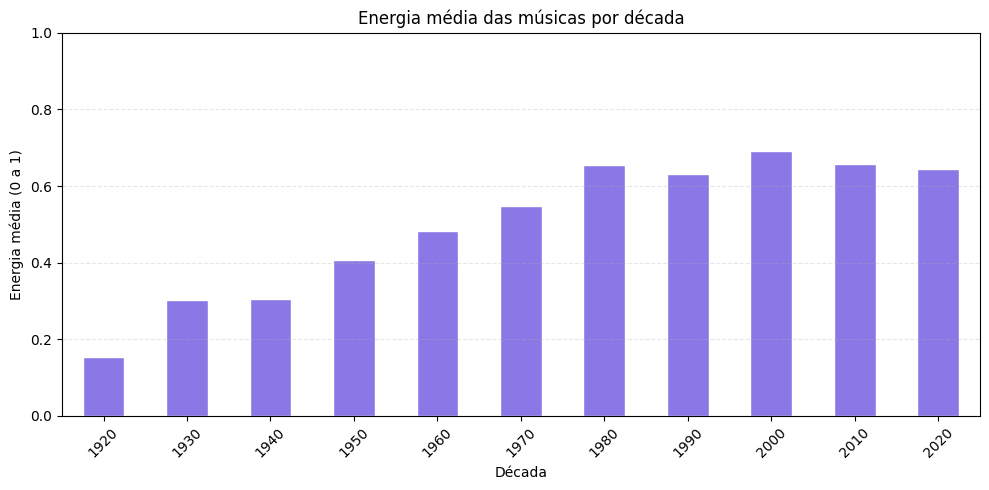

In [ ]:

plt.figure(figsize=(10, 5))

energia_decada.plot(
    kind="bar",
    color="#8B78E6",
    edgecolor="white"
)

plt.title("Energia média das músicas por década")
plt.xlabel("Década")
plt.ylabel("Energia média (0 a 1)")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

dancabilidade_decada = (
    df_com_ano
    .groupby("decada")["danceability"]
    .mean()
    .round(3)
)

print("Dançabilidade média por década:")
display(dancabilidade_decada.to_frame())


Dançabilidade média por década:


,danceability
decada,
1920,0.671
1930,0.698
1940,0.479
1950,0.536
1960,0.509
1970,0.531
1980,0.559
1990,0.552
2000,0.538


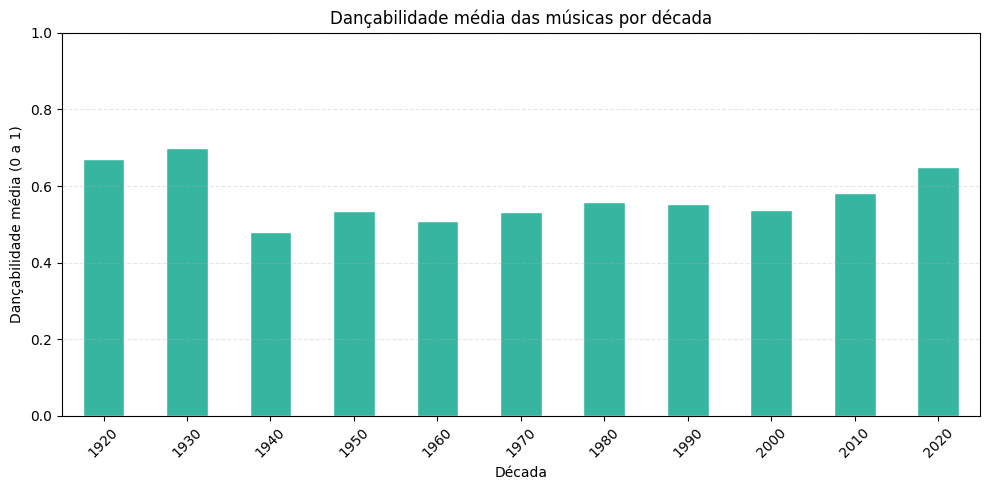

In [ ]:

plt.figure(figsize=(10, 5))

dancabilidade_decada.plot(
    kind="bar",
    color="#36B6A0",
    edgecolor="white"
)

plt.title("Dançabilidade média das músicas por década")
plt.xlabel("Década")
plt.ylabel("Dançabilidade média (0 a 1)")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Converter a duração de milissegundos para minutos
df_com_ano["duracao_minutos"] = (
    df_com_ano["duration_ms"] / 60000
)

# Calcular a duração média por década
duracao_decada = (
    df_com_ano
    .groupby("decada")["duracao_minutos"]
    .mean()
    .round(2)
)

print("Duração média das músicas por década (minutos):")
display(duracao_decada.to_frame())


Duração média das músicas por década (minutos):


,duracao_minutos
decada,
1920,2.26
1930,2.53
1940,2.80
1950,2.90
1960,3.14
1970,4.16
1980,4.16
1990,4.28
2000,4.20


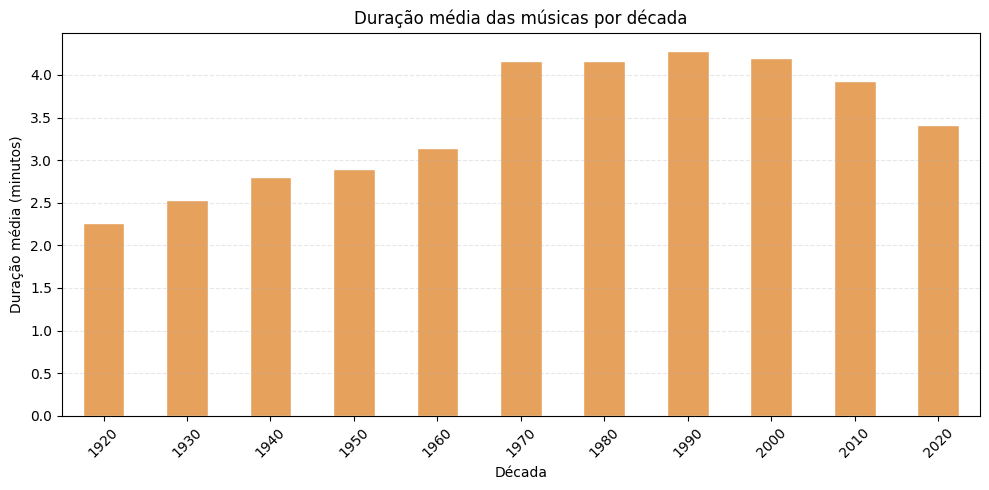

In [ ]:

plt.figure(figsize=(10, 5))

duracao_decada.plot(
    kind="bar",
    color="#E6A15C",
    edgecolor="white"
)

plt.title("Duração média das músicas por década")
plt.xlabel("Década")
plt.ylabel("Duração média (minutos)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Calcular a porcentagem de músicas explícitas por década
explicitas_decada = (
    df_com_ano
    .groupby("decada")["explicit"]
    .mean()
    .mul(100)
    .round(2)
)

print("Percentual de músicas explícitas por década:")
display(explicitas_decada.to_frame(name="percentual_explicitas"))


Percentual de músicas explícitas por década:


,percentual_explicitas
decada,
1920,0.00
1930,0.00
1940,0.00
1950,0.00
1960,0.11
1970,0.85
1980,1.89
1990,5.87
2000,5.03


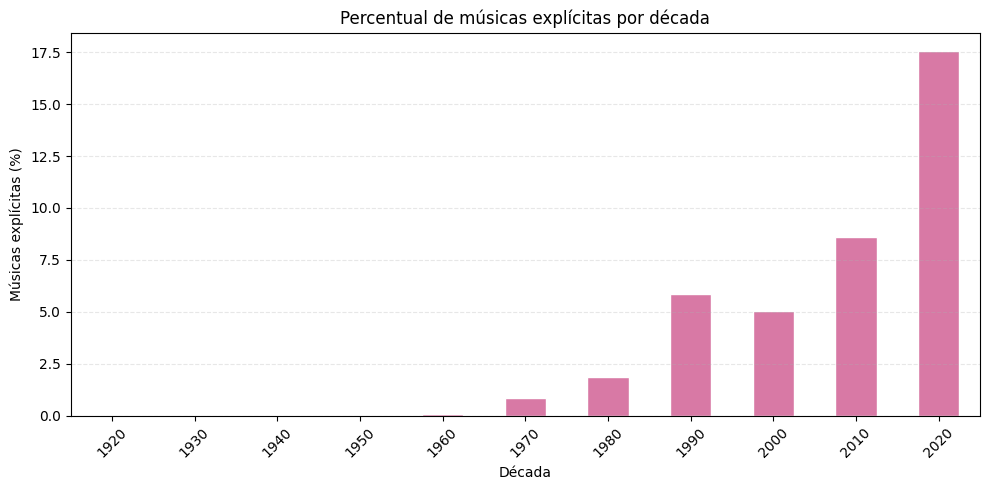

In [ ]:

plt.figure(figsize=(10, 5))

explicitas_decada.plot(
    kind="bar",
    color="#D879A5",
    edgecolor="white"
)

plt.title("Percentual de músicas explícitas por década")
plt.xlabel("Década")
plt.ylabel("Músicas explícitas (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


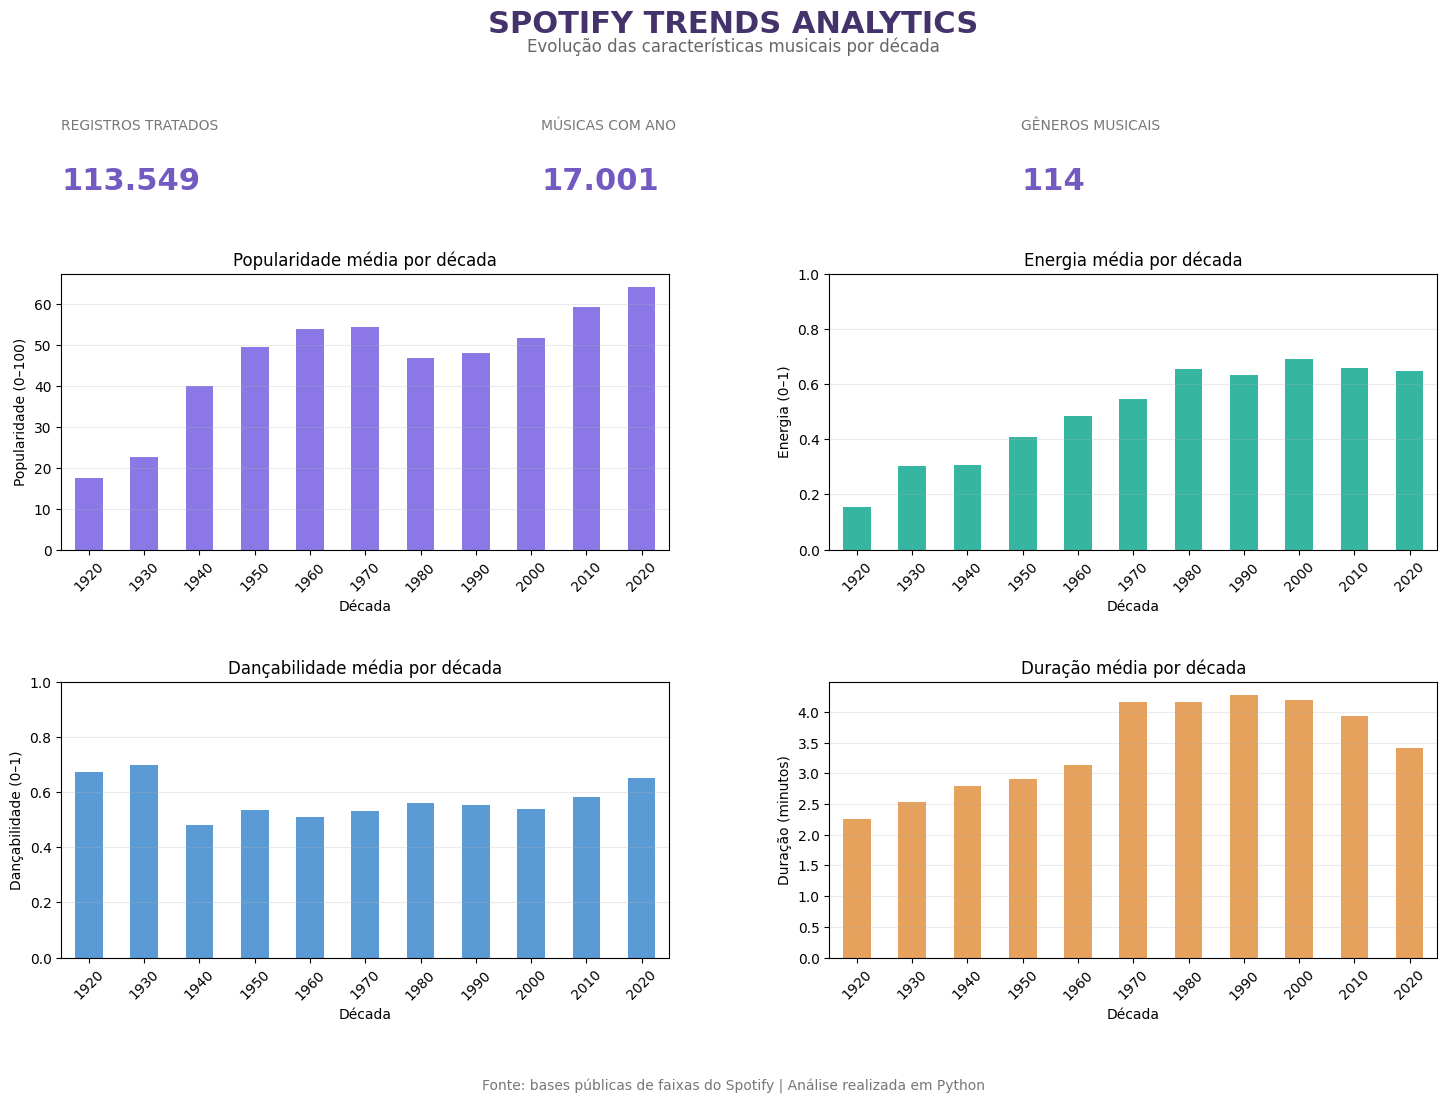

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Criar a figura principal do dashboard
fig = plt.figure(figsize=(16, 12))
fig.suptitle(
    "SPOTIFY TRENDS ANALYTICS",
    fontsize=22,
    fontweight="bold",
    color="#44336B",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Evolução das características musicais por década",
    ha="center",
    fontsize=12,
    color="#666666"
)

# Indicadores principais
kpis = [
    ("REGISTROS TRATADOS", f"{len(df_limpo):,}".replace(",", ".")),
    (
        "MÚSICAS COM ANO",
        f"{df_lancamentos['id'].nunique():,}".replace(",", ".")
    ),
    ("GÊNEROS MUSICAIS", f"{df_limpo['track_genre'].nunique()}")
]

posicoes = [0.08, 0.38, 0.68]

for (titulo, valor), x in zip(kpis, posicoes):
    fig.text(
        x, 0.88, titulo,
        fontsize=10, color="#777777"
    )
    fig.text(
        x, 0.83, valor,
        fontsize=22, fontweight="bold", color="#725AC1"
    )

# Organizar os quatro gráficos
ax1 = fig.add_axes([0.08, 0.53, 0.38, 0.23])
ax2 = fig.add_axes([0.56, 0.53, 0.38, 0.23])
ax3 = fig.add_axes([0.08, 0.19, 0.38, 0.23])
ax4 = fig.add_axes([0.56, 0.19, 0.38, 0.23])

# Gráfico 1: popularidade
popularidade_decada.plot(
    kind="bar", ax=ax1, color="#8B78E6"
)
ax1.set_title("Popularidade média por década")
ax1.set_xlabel("Década")
ax1.set_ylabel("Popularidade (0–100)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", alpha=0.25)

# Gráfico 2: energia
energia_decada.plot(
    kind="bar", ax=ax2, color="#36B6A0"
)
ax2.set_title("Energia média por década")
ax2.set_xlabel("Década")
ax2.set_ylabel("Energia (0–1)")
ax2.set_ylim(0, 1)
ax2.tick_params(axis="x", rotation=45)
ax2.grid(axis="y", alpha=0.25)

# Gráfico 3: dançabilidade
dancabilidade_decada.plot(
    kind="bar", ax=ax3, color="#5B9BD5"
)
ax3.set_title("Dançabilidade média por década")
ax3.set_xlabel("Década")
ax3.set_ylabel("Dançabilidade (0–1)")
ax3.set_ylim(0, 1)
ax3.tick_params(axis="x", rotation=45)
ax3.grid(axis="y", alpha=0.25)

# Gráfico 4: duração
duracao_decada.plot(
    kind="bar", ax=ax4, color="#E6A15C"
)
ax4.set_title("Duração média por década")
ax4.set_xlabel("Década")
ax4.set_ylabel("Duração (minutos)")
ax4.tick_params(axis="x", rotation=45)
ax4.grid(axis="y", alpha=0.25)

# Ajustes finais
fig.text(
    0.5, 0.08,
    "Fonte: bases públicas de faixas do Spotify | "
    "Análise realizada em Python",
    ha="center", fontsize=10, color="#777777"
)

plt.show()


In [ ]:

from pathlib import Path

Path("app.py").write_text(
    "# Spotify Trends Analytics\n"
    "# Dashboard interativo desenvolvido em Python.\n",
    encoding="utf-8"
)

print("Arquivo app.py criado com sucesso!")


Arquivo app.py criado com sucesso!


In [ ]:

%pip install -q streamlit plotly


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.7 MB/s eta 0:00:00


In [ ]:

import streamlit
import plotly

print("Streamlit:", streamlit.__version__)
print("Plotly:", plotly.__version__)
print("Tudo pronto para criar o dashboard!")


Streamlit: 1.66.1
Plotly: 5.24.1
Tudo pronto para criar o dashboard!


In [ ]:

# Preparar os dados que serão usados no dashboard

import pandas as pd

# Conferir se a base final continua disponível
print("Base final carregada:", "df_final" in globals())

# Criar a coluna de década, caso ainda não exista
if "decada" not in df_final.columns:
    df_final["decada"] = (
        (df_final["ano_lancamento"] // 10) * 10
    ).astype("Int64")

# Selecionar somente as colunas necessárias para o site
colunas_dashboard = [
    "track_id",
    "popularity",
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "track_genre",
    "ano_lancamento",
    "decada"
]

df_dashboard = df_final[colunas_dashboard].copy()

# Salvar o arquivo que será usado pelo aplicativo
df_dashboard.to_csv(
    "spotify_dashboard.csv",
    index=False
)

print("Arquivo preparado com sucesso!")
print("Quantidade de registros:", len(df_dashboard))
print("Colunas:", df_dashboard.columns.tolist())
print("Arquivo: spotify_dashboard.csv")


Base final carregada: True
Arquivo preparado com sucesso!
Quantidade de registros: 113549
Colunas: ['track_id', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'track_genre', 'ano_lancamento', 'decada']
Arquivo: spotify_dashboard.csv


In [ ]:

codigo_app = r'''
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

# --------------------------------------------------
# CONFIGURACAO DA PAGINA
# --------------------------------------------------
st.set_page_config(
    page_title="Spotify Trends Analytics",
    page_icon="🎧",
    layout="wide",
    initial_sidebar_state="expanded"
)

ROXO = "#7651A8"
VERDE = "#45B69C"
FUNDO = "#F7F6FA"

st.markdown("""
<style>
    .stApp { background-color: #F7F6FA; }
    h1, h2, h3 { color: #33264A; }
    div[data-testid="stMetric"] {
        background: white;
        border: 1px solid #E7E0F0;
        padding: 18px;
        border-radius: 14px;
    }
    div[data-testid="stMetricLabel"] { color: #6C617A; }
    .subtitulo { color: #71677D; font-size: 1rem; }
    section[data-testid="stSidebar"] {
        background-color: #F0ECF7;
    }
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# CARREGAMENTO DOS DADOS
# --------------------------------------------------
CAMINHO_DADOS = Path(__file__).parent / "data" / "spotify_dashboard.csv"

@st.cache_data
def carregar_dados(caminho):
    dados = pd.read_csv(caminho)

    dados["ano_lancamento"] = pd.to_numeric(
        dados["ano_lancamento"], errors="coerce"
    )
    dados["decada"] = pd.to_numeric(
        dados["decada"], errors="coerce"
    )
    dados["duration_min"] = dados["duration_ms"] / 60000

    dados["explicit"] = (
        dados["explicit"].astype(str).str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

    return dados

if not CAMINHO_DADOS.exists():
    st.error(
        "Arquivo de dados não encontrado. "
        "Verifique se spotify_dashboard.csv está dentro da pasta data."
    )
    st.stop()

df = carregar_dados(str(CAMINHO_DADOS))

# --------------------------------------------------
# CABECALHO
# --------------------------------------------------
st.title("🎧 Spotify Trends Analytics")
st.markdown(
    '<p class="subtitulo">Uma análise das características musicais '
    'e das tendências do Spotify ao longo das décadas.</p>',
    unsafe_allow_html=True
)
st.divider()

# --------------------------------------------------
# FILTROS
# --------------------------------------------------
st.sidebar.title("Explorar os dados")
st.sidebar.caption("Personalize sua visualização")

generos = sorted(df["track_genre"].dropna().unique().tolist())
generos_selecionados = st.sidebar.multiselect(
    "Gêneros musicais",
    options=generos,
    default=generos
)

decadas_disponiveis = sorted(
    df["decada"].dropna().astype(int).unique().tolist()
)
decadas_selecionadas = st.sidebar.multiselect(
    "Décadas de lançamento",
    options=decadas_disponiveis,
    default=decadas_disponiveis
)

df_filtrado = df[
    df["track_genre"].isin(generos_selecionados)
    & df["decada"].isin(decadas_selecionadas)
].copy()

df_com_ano = df_filtrado.dropna(subset=["ano_lancamento"])
df_sem_ano = df_filtrado[df_filtrado["ano_lancamento"].isna()]

if df_filtrado.empty:
    st.warning("Nenhum registro corresponde aos filtros selecionados.")
    st.stop()

# --------------------------------------------------
# INDICADORES
# --------------------------------------------------
faixas_com_ano = df_com_ano["track_id"].nunique()
total_generos = df_filtrado["track_genre"].nunique()
popularidade_media = df_filtrado["popularity"].mean()

c1, c2, c3, c4 = st.columns(4)
c1.metric("Registros analisados", f"{len(df_filtrado):,}".replace(",", "."))
c2.metric("Faixas com ano identificado", f"{faixas_com_ano:,}".replace(",", "."))
c3.metric("Gêneros selecionados", total_generos)
c4.metric("Popularidade média", f"{popularidade_media:.1f}/100")

st.caption(
    "Os indicadores e gráficos respondem aos filtros selecionados. "
    "Uma mesma faixa pode aparecer em mais de um gênero na base original."
)

# --------------------------------------------------
# GRAFICOS
# --------------------------------------------------
st.subheader("Características musicais ao longo das décadas")

if df_com_ano.empty:
    st.info("Não há anos de lançamento disponíveis para os filtros selecionados.")
else:
    resumo = (
        df_com_ano.groupby("decada", as_index=False)
        .agg(
            popularidade=("popularity", "mean"),
            energia=("energy", "mean"),
            dancabilidade=("danceability", "mean"),
            duracao=("duration_min", "mean"),
            registros=("track_id", "size"),
            faixas=("track_id", "nunique")
        )
        .sort_values("decada")
    )

    resumo["Década"] = resumo["decada"].astype(int).astype(str) + "s"

    col1, col2 = st.columns(2)

    with col1:
        fig = px.bar(
            resumo, x="Década", y="popularidade",
            title="Popularidade média por década",
            labels={"popularidade": "Popularidade média", "Década": ""},
            color_discrete_sequence=[ROXO],
            hover_data={"popularidade": ":.2f", "registros": True, "faixas": True}
        )
        fig.update_layout(template="plotly_white")
        st.plotly_chart(fig, use_container_width=True)

    with col2:
        fig = px.line(
            resumo, x="Década", y="energia",
            title="Energia musical por década",
            markers=True,
            labels={"energia": "Energia média", "Década": ""},
            color_discrete_sequence=[VERDE],
            hover_data={"energia": ":.3f", "registros": True}
        )
        fig.update_layout(template="plotly_white")
        st.plotly_chart(fig, use_container_width=True)

    col3, col4 = st.columns(2)

    with col3:
        fig = px.bar(
            resumo, x="Década", y="dancabilidade",
            title="Dançabilidade média por década",
            labels={"dancabilidade": "Dançabilidade média", "Década": ""},
            color_discrete_sequence=[VERDE],
            hover_data={"dancabilidade": ":.3f", "faixas": True}
        )
        fig.update_layout(template="plotly_white")
        st.plotly_chart(fig, use_container_width=True)

    with col4:
        fig = px.line(
            resumo, x="Década", y="duracao",
            title="Duração média das faixas",
            markers=True,
            labels={"duracao": "Duração (minutos)", "Década": ""},
            color_discrete_sequence=[ROXO],
            hover_data={"duracao": ":.2f", "registros": True}
        )
        fig.update_layout(template="plotly_white")
        st.plotly_chart(fig, use_container_width=True)

    explicitas = (
        df_com_ano.dropna(subset=["explicit"])
        .groupby("decada", as_index=False)
        .agg(percentual_explicitas=("explicit", lambda x: x.mean() * 100))
        .sort_values("decada")
    )
    explicitas["Década"] = explicitas["decada"].astype(int).astype(str) + "s"

    fig = px.bar(
        explicitas, x="Década", y="percentual_explicitas",
        title="Percentual de faixas marcadas como explícitas",
        labels={"percentual_explicitas": "Faixas explícitas (%)", "Década": ""},
        color_discrete_sequence=[ROXO]
    )
    fig.update_layout(template="plotly_white")
    st.plotly_chart(fig, use_container_width=True)

    with st.expander("Consultar tabela-resumo"):
        st.dataframe(
            resumo[[
                "Década", "popularidade", "energia",
                "dancabilidade", "duracao", "registros", "faixas"
            ]].round(3),
            use_container_width=True,
            hide_index=True
        )

# --------------------------------------------------
# METODOLOGIA E LIMITACOES
# --------------------------------------------------
st.divider()
with st.expander("Sobre os dados e a metodologia"):
    st.markdown("""
    **Objetivo:** explorar como características musicais variam entre faixas
    associadas a diferentes décadas de lançamento.

    **Tratamento:** os dados foram limpos e preparados previamente em um
    notebook Python. Os gráficos são calculados a partir da base tratada.

    **Cobertura dos anos:** o ano de lançamento foi complementado com uma
    segunda fonte. Nem todas as faixas tiveram correspondência; por isso,
    as análises por década usam somente os registros com ano identificado.

    **Interpretação:** a popularidade exibida é a disponível na base consultada,
    e não uma medida histórica da popularidade da música no ano em que foi lançada.
    As décadas antigas têm menos registros e os anos 2020 estão representados
    apenas parcialmente. Essas limitações devem ser consideradas nas conclusões.
    """)

st.caption("Projeto acadêmico de análise de dados com Python, Pandas, Plotly e Streamlit.")
'''

from pathlib import Path
Path("app.py").write_text(codigo_app, encoding="utf-8")

print("Arquivo app.py criado com o código do dashboard!")
print("Tamanho:", Path("app.py").stat().st_size, "bytes")


Arquivo app.py criado com o código do dashboard!
Tamanho: 8701 bytes


In [ ]:

from pathlib import Path

Path("requirements.txt").write_text(
    "streamlit\npandas\nplotly\n",
    encoding="utf-8"
)

print("Arquivo requirements.txt criado!")


Arquivo requirements.txt criado!


In [ ]:

from pathlib import Path

for nome in [
    "app.py",
    "requirements.txt",
    "spotify_dashboard.csv"
]:
    arquivo = Path(nome)
    print(
        f"{nome}: "
        + ("OK" if arquivo.exists() else "NÃO ENCONTRADO")
        + (f" ({arquivo.stat().st_size:,} bytes)" if arquivo.exists() else "")
    )


app.py: OK (8,701 bytes)
requirements.txt: OK (24 bytes)
spotify_dashboard.csv: OK (7,065,021 bytes)


In [ ]:

from google.colab import files

files.download("app.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

# Configuração da página
st.set_page_config(
    page_title="Spotify Trends Analytics",
    page_icon="🎵",
    layout="wide"
)

# Identidade visual
ROXO = "#7651A8"
VERDE = "#45B69C"

st.markdown(
    f"""
    <style>
    .stApp {{
        background-color: #FAF8FC;
    }}
    h1, h2, h3 {{
        color: {ROXO};
    }}
    [data-testid="stMetric"] {{
        background-color: white;
        border: 1px solid #E9E1F2;
        padding: 16px;
        border-radius: 12px;
    }}
    </style>
    """,
    unsafe_allow_html=True
)

# Localiza o CSV na pasta principal ou em /data
pasta = Path(__file__).parent
candidatos = [
    pasta / "spotify_dashboard.csv",
    pasta / "data" / "spotify_dashboard.csv"
]

arquivo_csv = next(
    (arquivo for arquivo in candidatos if arquivo.exists()),
    None
)

st.title("🎵 Spotify Trends Analytics")
st.caption("Evolução das características musicais por década")

if arquivo_csv is None:
    st.error(
        "Não encontrei spotify_dashboard.csv. "
        "Coloque o arquivo na mesma pasta do app.py "
        "ou dentro de uma pasta chamada data."
    )
    st.stop()


@st.cache_data
def carregar_dados(caminho):
    dados = pd.read_csv(caminho)

    dados["ano_lancamento"] = pd.to_numeric(
        dados["ano_lancamento"], errors="coerce"
    )
    dados["decada"] = pd.to_numeric(
        dados["decada"], errors="coerce"
    )

    dados["duracao_min"] = dados["duration_ms"] / 60000

    dados["explicit"] = (
        dados["explicit"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

    return dados


df = carregar_dados(str(arquivo_csv))

# Filtros
st.sidebar.header("Filtros")

generos = sorted(df["track_genre"].dropna().unique().tolist())
generos_selecionados = st.sidebar.multiselect(
    "Gêneros musicais",
    options=generos,
    default=generos
)

decadas_disponiveis = sorted(
    df["decada"].dropna().astype(int).unique().tolist()
)
decadas_selecionadas = st.sidebar.multiselect(
    "Décadas de lançamento",
    options=decadas_disponiveis,
    default=decadas_disponiveis
)

# Base filtrada por gênero para os indicadores gerais
df_generos = df[df["track_genre"].isin(generos_selecionados)].copy()

# Base com ano identificado para as análises por década
df_analise = df_generos[
    df_generos["decada"].isin(decadas_selecionadas)
].copy()

if df_analise.empty:
    st.warning("Nenhum registro encontrado com os filtros selecionados.")
    st.stop()

# Indicadores
total_registros = len(df_generos)
faixas_com_ano = df_generos["track_id"][
    df_generos["ano_lancamento"].notna()
].nunique()
total_generos = df_generos["track_genre"].nunique()
popularidade_media = df_analise["popularity"].mean()

c1, c2, c3, c4 = st.columns(4)

c1.metric("Registros", f"{total_registros:,}".replace(",", "."))
c2.metric("Músicas com ano", f"{faixas_com_ano:,}".replace(",", "."))
c3.metric("Gêneros", total_generos)
c4.metric(
    "Popularidade média",
    f"{popularidade_media:.1f}" if pd.notna(popularidade_media) else "—"
)

st.divider()

# Resumo por década
resumo = (
    df_analise.groupby("decada", as_index=False)
    .agg(
        popularidade_media=("popularity", "mean"),
        energia_media=("energy", "mean"),
        dancabilidade_media=("danceability", "mean"),
        duracao_media=("duracao_min", "mean"),
        percentual_explicitas=("explicit", "mean"),
        quantidade=("track_id", "size")
    )
    .sort_values("decada")
)

resumo["decada"] = resumo["decada"].astype(int).astype(str) + "s"
resumo["percentual_explicitas"] *= 100

# Gráficos
st.subheader("Popularidade média por década")
fig1 = px.bar(
    resumo, x="decada", y="popularidade_media",
    labels={
        "decada": "Década",
        "popularidade_media": "Popularidade média"
    },
    color_discrete_sequence=[ROXO]
)
fig1.update_layout(xaxis_title="Década", yaxis_title="Popularidade média")
st.plotly_chart(fig1, use_container_width=True)

coluna1, coluna2 = st.columns(2)

with coluna1:
    st.subheader("Energia média")
    fig2 = px.line(
        resumo, x="decada", y="energia_media",
        markers=True,
        labels={
            "decada": "Década",
            "energia_media": "Energia média"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig2, use_container_width=True)

with coluna2:
    st.subheader("Dançabilidade média")
    fig3 = px.bar(
        resumo, x="decada", y="dancabilidade_media",
        labels={
            "decada": "Década",
            "dancabilidade_media": "Dançabilidade média"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig3, use_container_width=True)

coluna3, coluna4 = st.columns(2)

with coluna3:
    st.subheader("Duração média das músicas")
    fig4 = px.line(
        resumo, x="decada", y="duracao_media",
        markers=True,
        labels={
            "decada": "Década",
            "duracao_media": "Duração média (minutos)"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig4, use_container_width=True)

with coluna4:
    st.subheader("Músicas explícitas por década")
    fig5 = px.bar(
        resumo, x="decada", y="percentual_explicitas",
        labels={
            "decada": "Década",
            "percentual_explicitas": "Músicas explícitas (%)"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig5, use_container_width=True)

# Tabela
st.subheader("Resumo dos dados por década")
st.dataframe(resumo, use_container_width=True, hide_index=True)

# Metodologia e limitações
with st.expander("Metodologia e limitações"):
    st.markdown("""
    - A base principal contém músicas e características musicais do Spotify.
    - Os dados passaram por tratamento de valores ausentes e registros repetidos.
    - Os anos de lançamento foram complementados com uma segunda base de dados.
    - Nem todas as músicas possuem ano de lançamento identificado; por isso,
      as análises por década utilizam somente os registros com ano disponível.
    - A popularidade representa uma medida atual do Spotify, não a popularidade
      histórica que a música tinha quando foi lançada.
    - As décadas mais antigas possuem menos registros e a década de 2020 está
      representada apenas parcialmente.
    - Os resultados descrevem os dados disponíveis e não necessariamente todo
      o universo musical de cada época.
    """)

st.caption("Projeto acadêmico de Big Data — Spotify Trends Analytics")


ModuleNotFoundError: No module named 'streamlit'

In [ ]:
%pip install -q streamlit plotly pandas

In [ ]:

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

# Configuração da página
st.set_page_config(
    page_title="Spotify Trends Analytics",
    page_icon="🎵",
    layout="wide"
)

# Identidade visual
ROXO = "#7651A8"
VERDE = "#45B69C"

st.markdown(
    f"""
    <style>
    .stApp {{
        background-color: #FAF8FC;
    }}
    h1, h2, h3 {{
        color: {ROXO};
    }}
    [data-testid="stMetric"] {{
        background-color: white;
        border: 1px solid #E9E1F2;
        padding: 16px;
        border-radius: 12px;
    }}
    </style>
    """,
    unsafe_allow_html=True
)

# Localiza o CSV na pasta principal ou em /data
pasta = Path("/content")
candidatos = [
    pasta / "spotify_dashboard.csv",
    pasta / "data" / "spotify_dashboard.csv"
]

arquivo_csv = next(
    (arquivo for arquivo in candidatos if arquivo.exists()),
    None
)

st.title("🎵 Spotify Trends Analytics")
st.caption("Evolução das características musicais por década")

if arquivo_csv is None:
    st.error(
        "Não encontrei spotify_dashboard.csv. "
        "Coloque o arquivo na mesma pasta do app.py "
        "ou dentro de uma pasta chamada data."
    )
    st.stop()


@st.cache_data
def carregar_dados(caminho):
    dados = pd.read_csv(caminho)

    dados["ano_lancamento"] = pd.to_numeric(
        dados["ano_lancamento"], errors="coerce"
    )
    dados["decada"] = pd.to_numeric(
        dados["decada"], errors="coerce"
    )

    dados["duracao_min"] = dados["duration_ms"] / 60000

    dados["explicit"] = (
        dados["explicit"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

    return dados


df = carregar_dados(str(arquivo_csv))

# Filtros
st.sidebar.header("Filtros")

generos = sorted(df["track_genre"].dropna().unique().tolist())
generos_selecionados = st.sidebar.multiselect(
    "Gêneros musicais",
    options=generos,
    default=generos
)

decadas_disponiveis = sorted(
    df["decada"].dropna().astype(int).unique().tolist()
)
decadas_selecionadas = st.sidebar.multiselect(
    "Décadas de lançamento",
    options=decadas_disponiveis,
    default=decadas_disponiveis
)

# Base filtrada por gênero para os indicadores gerais
df_generos = df[df["track_genre"].isin(generos_selecionados)].copy()

# Base com ano identificado para as análises por década
df_analise = df_generos[
    df_generos["decada"].isin(decadas_selecionadas)
].copy()

if df_analise.empty:
    st.warning("Nenhum registro encontrado com os filtros selecionados.")
    st.stop()

# Indicadores
total_registros = len(df_generos)
faixas_com_ano = df_generos["track_id"][
    df_generos["ano_lancamento"].notna()
].nunique()
total_generos = df_generos["track_genre"].nunique()
popularidade_media = df_analise["popularity"].mean()

c1, c2, c3, c4 = st.columns(4)

c1.metric("Registros", f"{total_registros:,}".replace(",", "."))
c2.metric("Músicas com ano", f"{faixas_com_ano:,}".replace(",", "."))
c3.metric("Gêneros", total_generos)
c4.metric(
    "Popularidade média",
    f"{popularidade_media:.1f}" if pd.notna(popularidade_media) else "—"
)

st.divider()

# Resumo por década
resumo = (
    df_analise.groupby("decada", as_index=False)
    .agg(
        popularidade_media=("popularity", "mean"),
        energia_media=("energy", "mean"),
        dancabilidade_media=("danceability", "mean"),
        duracao_media=("duracao_min", "mean"),
        percentual_explicitas=("explicit", "mean"),
        quantidade=("track_id", "size")
    )
    .sort_values("decada")
)

resumo["decada"] = resumo["decada"].astype(int).astype(str) + "s"
resumo["percentual_explicitas"] *= 100

# Gráficos
st.subheader("Popularidade média por década")
fig1 = px.bar(
    resumo, x="decada", y="popularidade_media",
    labels={
        "decada": "Década",
        "popularidade_media": "Popularidade média"
    },
    color_discrete_sequence=[ROXO]
)
fig1.update_layout(xaxis_title="Década", yaxis_title="Popularidade média")
st.plotly_chart(fig1, use_container_width=True)

coluna1, coluna2 = st.columns(2)

with coluna1:
    st.subheader("Energia média")
    fig2 = px.line(
        resumo, x="decada", y="energia_media",
        markers=True,
        labels={
            "decada": "Década",
            "energia_media": "Energia média"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig2, use_container_width=True)

with coluna2:
    st.subheader("Dançabilidade média")
    fig3 = px.bar(
        resumo, x="decada", y="dancabilidade_media",
        labels={
            "decada": "Década",
            "dancabilidade_media": "Dançabilidade média"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig3, use_container_width=True)

coluna3, coluna4 = st.columns(2)

with coluna3:
    st.subheader("Duração média das músicas")
    fig4 = px.line(
        resumo, x="decada", y="duracao_media",
        markers=True,
        labels={
            "decada": "Década",
            "duracao_media": "Duração média (minutos)"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig4, use_container_width=True)

with coluna4:
    st.subheader("Músicas explícitas por década")
    fig5 = px.bar(
        resumo, x="decada", y="percentual_explicitas",
        labels={
            "decada": "Década",
            "percentual_explicitas": "Músicas explícitas (%)"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig5, use_container_width=True)

# Tabela
st.subheader("Resumo dos dados por década")
st.dataframe(resumo, use_container_width=True, hide_index=True)

# Metodologia e limitações
with st.expander("Metodologia e limitações"):
    st.markdown("""
    - A base principal contém músicas e características musicais do Spotify.
    - Os dados passaram por tratamento de valores ausentes e registros repetidos.
    - Os anos de lançamento foram complementados com uma segunda base de dados.
    - Nem todas as músicas possuem ano de lançamento identificado; por isso,
      as análises por década utilizam somente os registros com ano disponível.
    - A popularidade representa uma medida atual do Spotify, não a popularidade
      histórica que a música tinha quando foi lançada.
    - As décadas mais antigas possuem menos registros e a década de 2020 está
      representada apenas parcialmente.
    - Os resultados descrevem os dados disponíveis e não necessariamente todo
      o universo musical de cada época.
    """)

st.caption("Projeto acadêmico de Big Data — Spotify Trends Analytics")


2026-10-27 13:28:21.296 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:28:21.298 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:28:21.447 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-27 13:28:21.448 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:28:21.449 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NameError: name '__file__' is not defined

In [ ]:

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

# Configuração da página
st.set_page_config(
    page_title="Spotify Trends Analytics",
    page_icon="🎵",
    layout="wide"
)

# Identidade visual
ROXO = "#7651A8"
VERDE = "#45B69C"

st.markdown(
    f"""
    <style>
    .stApp {{
        background-color: #FAF8FC;
    }}
    h1, h2, h3 {{
        color: {ROXO};
    }}
    [data-testid="stMetric"] {{
        background-color: white;
        border: 1px solid #E9E1F2;
        padding: 16px;
        border-radius: 12px;
    }}
    </style>
    """,
    unsafe_allow_html=True
)

# Localiza o CSV na pasta principal ou em /data
pasta = Path("/content")
candidatos = [
    pasta / "spotify_dashboard.csv",
    pasta / "data" / "spotify_dashboard.csv"
]

arquivo_csv = next(
    (arquivo for arquivo in candidatos if arquivo.exists()),
    None
)

st.title("🎵 Spotify Trends Analytics")
st.caption("Evolução das características musicais por década")

if arquivo_csv is None:
    st.error(
        "Não encontrei spotify_dashboard.csv. "
        "Coloque o arquivo na mesma pasta do app.py "
        "ou dentro de uma pasta chamada data."
    )
    st.stop()


@st.cache_data
def carregar_dados(caminho):
    dados = pd.read_csv(caminho)

    dados["ano_lancamento"] = pd.to_numeric(
        dados["ano_lancamento"], errors="coerce"
    )
    dados["decada"] = pd.to_numeric(
        dados["decada"], errors="coerce"
    )

    dados["duracao_min"] = dados["duration_ms"] / 60000

    dados["explicit"] = (
        dados["explicit"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )

    return dados


df = carregar_dados(str(arquivo_csv))

# Filtros
st.sidebar.header("Filtros")

generos = sorted(df["track_genre"].dropna().unique().tolist())
generos_selecionados = st.sidebar.multiselect(
    "Gêneros musicais",
    options=generos,
    default=generos
)

decadas_disponiveis = sorted(
    df["decada"].dropna().astype(int).unique().tolist()
)
decadas_selecionadas = st.sidebar.multiselect(
    "Décadas de lançamento",
    options=decadas_disponiveis,
    default=decadas_disponiveis
)

# Base filtrada por gênero para os indicadores gerais
df_generos = df[df["track_genre"].isin(generos_selecionados)].copy()

# Base com ano identificado para as análises por década
df_analise = df_generos[
    df_generos["decada"].isin(decadas_selecionadas)
].copy()

if df_analise.empty:
    st.warning("Nenhum registro encontrado com os filtros selecionados.")
    st.stop()

# Indicadores
total_registros = len(df_generos)
faixas_com_ano = df_generos["track_id"][
    df_generos["ano_lancamento"].notna()
].nunique()
total_generos = df_generos["track_genre"].nunique()
popularidade_media = df_analise["popularity"].mean()

c1, c2, c3, c4 = st.columns(4)

c1.metric("Registros", f"{total_registros:,}".replace(",", "."))
c2.metric("Músicas com ano", f"{faixas_com_ano:,}".replace(",", "."))
c3.metric("Gêneros", total_generos)
c4.metric(
    "Popularidade média",
    f"{popularidade_media:.1f}" if pd.notna(popularidade_media) else "—"
)

st.divider()

# Resumo por década
resumo = (
    df_analise.groupby("decada", as_index=False)
    .agg(
        popularidade_media=("popularity", "mean"),
        energia_media=("energy", "mean"),
        dancabilidade_media=("danceability", "mean"),
        duracao_media=("duracao_min", "mean"),
        percentual_explicitas=("explicit", "mean"),
        quantidade=("track_id", "size")
    )
    .sort_values("decada")
)

resumo["decada"] = resumo["decada"].astype(int).astype(str) + "s"
resumo["percentual_explicitas"] *= 100

# Gráficos
st.subheader("Popularidade média por década")
fig1 = px.bar(
    resumo, x="decada", y="popularidade_media",
    labels={
        "decada": "Década",
        "popularidade_media": "Popularidade média"
    },
    color_discrete_sequence=[ROXO]
)
fig1.update_layout(xaxis_title="Década", yaxis_title="Popularidade média")
st.plotly_chart(fig1, use_container_width=True)

coluna1, coluna2 = st.columns(2)

with coluna1:
    st.subheader("Energia média")
    fig2 = px.line(
        resumo, x="decada", y="energia_media",
        markers=True,
        labels={
            "decada": "Década",
            "energia_media": "Energia média"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig2, use_container_width=True)

with coluna2:
    st.subheader("Dançabilidade média")
    fig3 = px.bar(
        resumo, x="decada", y="dancabilidade_media",
        labels={
            "decada": "Década",
            "dancabilidade_media": "Dançabilidade média"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig3, use_container_width=True)

coluna3, coluna4 = st.columns(2)

with coluna3:
    st.subheader("Duração média das músicas")
    fig4 = px.line(
        resumo, x="decada", y="duracao_media",
        markers=True,
        labels={
            "decada": "Década",
            "duracao_media": "Duração média (minutos)"
        },
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig4, use_container_width=True)

with coluna4:
    st.subheader("Músicas explícitas por década")
    fig5 = px.bar(
        resumo, x="decada", y="percentual_explicitas",
        labels={
            "decada": "Década",
            "percentual_explicitas": "Músicas explícitas (%)"
        },
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig5, use_container_width=True)

# Tabela
st.subheader("Resumo dos dados por década")
st.dataframe(resumo, use_container_width=True, hide_index=True)

# Metodologia e limitações
with st.expander("Metodologia e limitações"):
    st.markdown("""
    - A base principal contém músicas e características musicais do Spotify.
    - Os dados passaram por tratamento de valores ausentes e registros repetidos.
    - Os anos de lançamento foram complementados com uma segunda base de dados.
    - Nem todas as músicas possuem ano de lançamento identificado; por isso,
      as análises por década utilizam somente os registros com ano disponível.
    - A popularidade representa uma medida atual do Spotify, não a popularidade
      histórica que a música tinha quando foi lançada.
    - As décadas mais antigas possuem menos registros e a década de 2020 está
      representada apenas parcialmente.
    - Os resultados descrevem os dados disponíveis e não necessariamente todo
      o universo musical de cada época.
    """)

st.caption("Projeto acadêmico de Big Data — Spotify Trends Analytics")


2026-10-27 13:32:15.370 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.372 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.373 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.376 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.379 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.380 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.381 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 13:32:15.382 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

FileNotFoundError: [Errno 2] No such file or directory: 'None'

In [ ]:
import os

print("Pasta atual:", os.getcwd())
print("\nArquivos disponíveis:")

for arquivo in os.listdir("/content"):
    print(arquivo)


Pasta atual: /content

Arquivos disponíveis:
.config
sample_data


In [ ]:
from google.colab import files
arquivos = files.upload()

Saving spotify_dashboard.csv to spotify_dashboard.csv


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'spotify_dashboard.csv', 'sample_data']


In [ ]:

from pathlib import Path

codigo_app = r'''
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(
    page_title="Spotify Trends Analytics",
    page_icon="🎵",
    layout="wide"
)

ROXO = "#7651A8"
VERDE = "#45B69C"

st.markdown("""
<style>
.stApp { background-color: #FAF8FC; }
h1, h2, h3 { color: #7651A8; }
[data-testid="stMetric"] {
    background-color: white;
    border: 1px solid #E9E1F2;
    padding: 16px;
    border-radius: 12px;
}
</style>
""", unsafe_allow_html=True)

pasta = Path(__file__).parent
opcoes_csv = [
    pasta / "spotify_dashboard.csv",
    pasta / "data" / "spotify_dashboard.csv"
]
arquivo_csv = next((p for p in opcoes_csv if p.exists()), None)

st.title("🎵 Spotify Trends Analytics")
st.caption("Evolução das características musicais por década")

if arquivo_csv is None:
    st.error("Não encontrei spotify_dashboard.csv. Coloque o arquivo na raiz do repositório ou na pasta data.")
    st.stop()

@st.cache_data
def carregar_dados(caminho):
    df = pd.read_csv(caminho)
    df["ano_lancamento"] = pd.to_numeric(df["ano_lancamento"], errors="coerce")
    df["decada"] = pd.to_numeric(df["decada"], errors="coerce")
    df["duracao_min"] = df["duration_ms"] / 60000
    df["explicit"] = (
        df["explicit"].astype(str).str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )
    return df

df = carregar_dados(str(arquivo_csv))

st.sidebar.header("Filtros")

generos = sorted(df["track_genre"].dropna().unique().tolist())
generos_escolhidos = st.sidebar.multiselect(
    "Gêneros musicais", generos, default=generos
)

decadas = sorted(df["decada"].dropna().astype(int).unique().tolist())
decadas_escolhidas = st.sidebar.multiselect(
    "Décadas de lançamento", decadas, default=decadas
)

df_generos = df[df["track_genre"].isin(generos_escolhidos)].copy()
df_analise = df_generos[
    df_generos["decada"].isin(decadas_escolhidas)
].copy()

if df_analise.empty:
    st.warning("Nenhum registro encontrado. Ajuste os filtros.")
    st.stop()

c1, c2, c3, c4 = st.columns(4)
c1.metric("Registros", f"{len(df_generos):,}".replace(",", "."))
c2.metric(
    "Músicas com ano",
    f"{df_generos.loc[df_generos['ano_lancamento'].notna(), 'track_id'].nunique():,}".replace(",", ".")
)
c3.metric("Gêneros", df_generos["track_genre"].nunique())
c4.metric("Popularidade média", f"{df_analise['popularity'].mean():.1f}")

resumo = df_analise.groupby("decada", as_index=False).agg(
    popularidade_media=("popularity", "mean"),
    energia_media=("energy", "mean"),
    dancabilidade_media=("danceability", "mean"),
    duracao_media=("duracao_min", "mean"),
    percentual_explicitas=("explicit", "mean"),
    quantidade=("track_id", "size")
).sort_values("decada")

resumo["decada_label"] = resumo["decada"].astype(int).astype(str) + "s"
resumo["percentual_explicitas"] *= 100

st.subheader("Popularidade média por década")
fig1 = px.bar(
    resumo, x="decada_label", y="popularidade_media",
    labels={"decada_label": "Década", "popularidade_media": "Popularidade média"},
    color_discrete_sequence=[ROXO]
)
st.plotly_chart(fig1, use_container_width=True)

col1, col2 = st.columns(2)

with col1:
    st.subheader("Energia média")
    fig2 = px.line(
        resumo, x="decada_label", y="energia_media", markers=True,
        labels={"decada_label": "Década", "energia_media": "Energia média"},
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig2, use_container_width=True)

with col2:
    st.subheader("Dançabilidade média")
    fig3 = px.bar(
        resumo, x="decada_label", y="dancabilidade_media",
        labels={"decada_label": "Década", "dancabilidade_media": "Dançabilidade média"},
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig3, use_container_width=True)

col3, col4 = st.columns(2)

with col3:
    st.subheader("Duração média das músicas")
    fig4 = px.line(
        resumo, x="decada_label", y="duracao_media", markers=True,
        labels={"decada_label": "Década", "duracao_media": "Duração média (minutos)"},
        color_discrete_sequence=[VERDE]
    )
    st.plotly_chart(fig4, use_container_width=True)

with col4:
    st.subheader("Músicas explícitas por década")
    fig5 = px.bar(
        resumo, x="decada_label", y="percentual_explicitas",
        labels={"decada_label": "Década", "percentual_explicitas": "Músicas explícitas (%)"},
        color_discrete_sequence=[ROXO]
    )
    st.plotly_chart(fig5, use_container_width=True)

st.subheader("Resumo por década")
st.dataframe(resumo.drop(columns=["decada_label"]), use_container_width=True, hide_index=True)

with st.expander("Metodologia e limitações"):
    st.markdown("""
    - A base principal contém características musicais e gêneros de faixas do Spotify.
    - Os dados foram tratados para remover registros repetidos e lidar com valores ausentes.
    - As datas de lançamento foram complementadas com uma segunda base.
    - Nem todas as faixas possuem ano identificado; as análises por década consideram apenas as datas disponíveis.
    - A popularidade representa uma medida atual do Spotify, não a popularidade histórica na época do lançamento.
    - As décadas antigas têm menos registros e os anos 2020 estão representados parcialmente.
    """)

st.caption("Projeto acadêmico de Big Data — Spotify Trends Analytics")
'''

Path("/content/app.py").write_text(codigo_app, encoding="utf-8")
Path("/content/requirements.txt").write_text(
    "streamlit\npandas\nplotly\n",
    encoding="utf-8"
)

print("Arquivos criados:")
print(Path("/content/app.py").exists(), "app.py")
print(Path("/content/requirements.txt").exists(), "requirements.txt")


Arquivos criados:
True app.py
True requirements.txt


In [ ]:
from google.colab import files
files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>